In [ ]:
####

### EV: main things to address here
###
### - correct volume factors / elements for distances
### - need a way to handle negatives from downsampling and rotation

####

In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [2]:
het_vol_files = 'Data/het_models/'

n_vols = 10

downsample = True
scale = 2

het_vols = []

vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
        
        if downsample:
            
            # v = transforms.fourier_downsample(v, 2, rescale=False)
            # v = np.where(v<0, 0, v)
            
            v = transforms.block_average_downsample(v, scale)
            dx = dx * scale
            
        # print(np.amin(v), np.amax(v), np.sum(v))
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
        print(np.amin(v), np.amax(v), np.sum(v), np.linalg.norm(v))
        print('\n')
        
        # v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
        het_vols.append(v)
        
        mrc.close()
        
dV = dx**3

het_vols = np.array(het_vols)

# F = het_vols[0].copy()  # the reference volume 
# print(F.shape)

with mrcfile.open(het_vol_files+'0.mrc', permissive=True) as mrc:
    v = mrc.data
    dx = mrc.voxel_size.x
    if downsample:
        v = transforms.block_average_downsample(v, scale)
        dx = dx * scale
    F = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
    # F = np.pad(F, pad_width=((0, 1), (0, 1), (0, 1)))

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


0.0 0.00035347196 0.125 0.0048207673


0.0 0.00035352627 0.125 0.0048829755


0.0 0.00035340482 0.12500001 0.0048224553


0.0 0.0003534762 0.125 0.0048067165


0.0 0.00035349402 0.12500001 0.0048087733


0.0 0.00035342216 0.125 0.004844837


0.0 0.0003534763 0.12500001 0.00483557


0.0 0.00035345327 0.12499999 0.004868386


0.0 0.00035351474 0.12499999 0.0048215888


0.0 0.00035346652 0.12500001 0.004829896




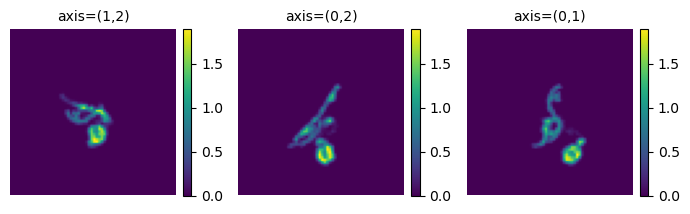

In [3]:
plots.orthogonal_2D_projection_plot(v)
# plots.orthogonal_2D_projection_plot(np.where(v>0, v, 0))
# plots.orthogonal_2D_projection_plot(np.where(v<0, v, 0))

In [ ]:
### EV: make better version to do all transforms at once later, but this is okay for now
### EV: first try without rotation

M = F.shape[0]   # grid size LxLxL
d = 3            # dimensons

# thetas = np.sin(np.linspace(0, np.pi, M, endpoint=True))
thetas = np.ones(M)

distances_sw = {}
distances_rfsw = {}
distances_l2 = {}

F = signals.Signal(F, d=3).preprocess_signals()[0]
F_t = transforms.Transform(F, d=3).inverse_cdf_transform()[0]

F_tp, F_tn = transforms.Transform(F, d=3, apply_ramp=True).signed_inverse_cdf_transform()

for k in range(n_vols):

    G = het_vols[k]
    
    t = time.time()

    G = signals.Signal(G, d=3).preprocess_signals()[0]
    distances_l2[k] = np.linalg.norm(F - G)
    
    G_t = transforms.Transform(G, d=3).inverse_cdf_transform()[0]
    distances_sw[k] = distances.sliced_distance_3d(F_t, G_t, thetas)

    G_tp, G_tn = transforms.Transform(G, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    distances_rfsw[k] = distances.signed_sliced_distance_3d(F_tp[0], G_tp[0], F_tn[0], G_tn[0], thetas)
    
    print("Vol {} alignment = ".format(vol_idx[k]), time.time() - t)

In [ ]:
dists_l2 = np.array([dist for k, dist in distances_l2.items()])
dists_sw = np.array([dist for k, dist in distances_sw.items()])
dists_rfsw = np.array([dist for k, dist in distances_rfsw.items()])

dists_l2 = np.sqrt( dists_l2 / np.amax(dists_l2) )
dists_sw = np.sqrt( dists_sw / np.amax(dists_sw) )
dists_rfsw = np.sqrt( dists_rfsw / np.amax(dists_rfsw) )

In [ ]:
print('  L2: ', dists_l2)
print('  SW: ', dists_sw)
print('RFSW: ', dists_rfsw)

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(vol_idx[:], dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
plt.plot(vol_idx[:], dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')
plt.plot(vol_idx[:], dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx, np.linspace(0, 1, 5))
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [ ]:
# plots.orthogonal_2D_projection_plot(het_vols[0])

# for k, v in het_vols.items():
#     plots.orthogonal_2D_projection_plot(het_vols[0] - v)

In [4]:
### EV: Now test with rotation

### 1) preprocess

np.random.seed(0)

metric = 'distance'

# omegas = np.deg2rad(np.random.randint(0, 360, n_vols))
# betas = np.deg2rad(np.random.randint(0, 180, n_vols))
# alphas = np.deg2rad(np.random.randint(0, 360, n_vols))

het_vols_rotated = []

print(np.amin(het_vols[0]), np.amax(het_vols[0]), np.sum(het_vols[0]))
print(np.sum(np.where(het_vols[0] < 0, het_vols[0], 0)), np.sum(np.where(het_vols[0] > 0, het_vols[0], 0)))
print('\n')

for idx in range(n_vols):
    # o, b, a = omegas[idx], betas[idx], alphas[idx]
    # rot_vol = transforms.rotate_voxel_zyz_fourier(het_vols[v_idx], o, b, a)

    ### EV: rotations that should not cause negative from interpolation
    ###     don't need to renormalize signal 
    ###     do either of these cause reflection?
    # rot_vol = het_vols[idx][::-1, :, ::-1]
    # rot_vol = np.rot90(het_vols[idx])  

    ### EV: or no rotation
    rot_vol = het_vols[idx]
    
    # print(np.amin(rot_vol), np.amax(rot_vol), np.sum(rot_vol))
    # print(np.sum(np.where(rot_vol < 0, rot_vol, 0)), np.sum(np.where(rot_vol > 0, rot_vol, 0)))
    # print('\n')
    
    # rot_vol = np.where(rot_vol<0, 0, rot_vol)
    # rot_vol -= np.amin(rot_vol)
    # rot_vol = signals.Signal(rot_vol, d=3).preprocess_signals()[0]
    # print(np.amin(rot_vol), np.amax(rot_vol), np.sum(rot_vol))
    
    het_vols_rotated.append(rot_vol)

het_vols_rotated = np.array(het_vols_rotated)

M = F.shape[0]   # grid size NxNxN
d = 3            # dimensons
max_l = M//2

N = F.shape[0]   # just to keep nomenclature

# thetas = np.linspace(0, np.pi, M, endpoint=True)[np.newaxis, :, np.newaxis]
thetas = np.ones(M)[np.newaxis, :, np.newaxis]

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

print(np.amin(F), np.amax(F), np.sum(F))

F_t = transforms.Transform(F, d=3).inverse_cdf_transform()[0]
F_tp, F_tn = transforms.Transform(F, d=3, apply_ramp=True).signed_inverse_cdf_transform()

F_norm = np.linalg.norm(F)
F_t_norm = np.linalg.norm(F_t)
F_tp_norm, F_tn_norm = np.linalg.norm(F_tp[0]), np.linalg.norm(F_tn[0])

0.0 0.00035347196 0.125
0.0 0.125


0.0 0.00035347196 0.125


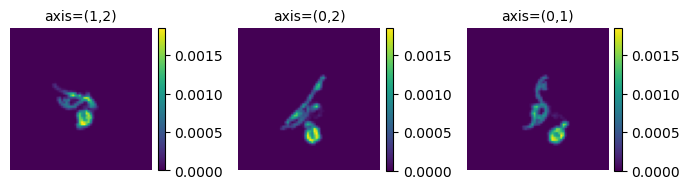

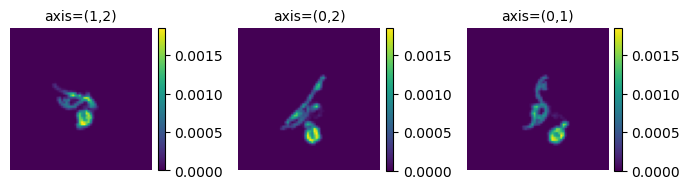

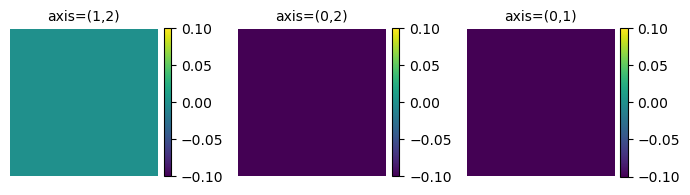

In [5]:
plots.orthogonal_2D_projection_plot(het_vols[0])
plots.orthogonal_2D_projection_plot(het_vols_rotated[0])
plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols_rotated[0])

In [6]:
# np.allclose(F, het_vols_rotated[0][::-1, :, ::-1])
# np.allclose(F, np.rot90(het_vols_rotated[0], -1))

In [7]:
# plots.orthogonal_2D_projection_plot(F)
# plots.orthogonal_2D_projection_plot(np.rot90(F,4))

In [8]:
### 2) compute distances

### EV: not including dV here yet, because its just global scaling ?

print(metric, '\n')

distances_l2, distances_sw, distances_rfsw = [], [], []
rot_matrices_l2, rot_matrices_sw, rot_matrices_rfsw = {}, {}, {}
het_vols_aligned_l2, het_vols_aligned_sw, het_vols_aligned_rfsw = {}, {}, {}


for k in range(n_vols):

    
    G = het_vols_rotated[k].copy()
    G_norm = np.linalg.norm(G)

    print('F: ', np.amin(F), np.amax(F), np.sum(F))
    print('G: ', np.amin(G), np.amax(G), np.sum(G))

    t = time.time()

    
    ###
    ### 1) COMPUTE EUCLIDEAN DISTANCE
    ###

     # need normalization from fle?
    c = alignments.align_l2(np.flip(F, axis=2), np.flip(G, axis=2), fle)[:-1, :-1, :-1].real * N**3
    # c = alignments.align_l2(F, G, fle).real * N**3

    if metric == 'correlation':
        c = c / (F_norm * G_norm)  # normalize for scaling / comparison ???
        distances_l2.append(np.amax(c))
        R_est = alignments.alignment_matrix_from_distances(c, corr=True)

    elif metric == 'distance':
        dists = F_norm**2 + G_norm**2 - 2*c
        distances_l2.append(np.amin(dists))
        R_est = alignments.alignment_matrix_from_distances(dists, corr=False)        

    rot_matrices_l2[vol_idx[k]] = R_est
    
    print("Vol {} alignment L2   = ".format(vol_idx[k]), time.time() - t)
    
    o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    het_vols_aligned_l2[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    
    ###
    ### 2) COMPUTE SLICED 2-WASSERSTEIN DISTANCE
    ###
    
    t = time.time()

    G_t = transforms.Transform(G, d=3).inverse_cdf_transform()[0]
    G_t_norm = np.linalg.norm(G_t)
    
    c = alignments.fast_rotational_correlation(F_t, G_t, fle)[:-1, :-1, :-1].real * N**3

    if metric == 'correlation':
        c = c / (F_t_norm * G_t_norm)
        distances_sw.append(np.amax(c))
        R_est = alignments.alignment_matrix_from_distances(c, corr=True)
    
    elif metric == 'distance':
        dists = ((F_t_norm * thetas)**2 + (G_t_norm * thetas)**2 - 2*c) / (4*np.pi)
        distances_sw.append(np.amin(dists))
        R_est = alignments.alignment_matrix_from_distances(dists, corr=False)
        
    rot_matrices_sw[vol_idx[k]] = R_est

    print("Vol {} alignment SW   = ".format(vol_idx[k]), time.time() - t)

    o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    het_vols_aligned_sw[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    
    ###
    ### 2) COMPUTE RAMP FILTERED SLICED 2-WASSERSTEIN DISTANCE
    ###    

    t = time.time()
    
    G_tp, G_tn = transforms.Transform(G, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    G_tp_norm, G_tn_norm = np.linalg.norm(G_tp[0]), np.linalg.norm(G_tn[0])
    
    
    cp = alignments.fast_rotational_correlation(F_tp[0], G_tp[0], fle)[:-1, :-1, :-1].real * N**3
    cn = alignments.fast_rotational_correlation(F_tn[0], G_tn[0], fle)[:-1, :-1, :-1].real * N**3

    if metric == 'correlation':
        cp = cp / (F_tp_norm * G_tp_norm)
        cn = cn / (F_tn_norm * G_tn_norm) 
        c = (cp + cn) / 2
        distances_rfsw.append(np.amax(c))
        R_est = alignments.alignment_matrix_from_distances(c, corr=True)
    
    elif metric == 'distance':
        dists_p = ((F_tp_norm * thetas)**2 + (G_tp_norm * thetas)**2 - 2*cp) / (4*np.pi)
        dists_n = ((F_tn_norm * thetas)**2 + (G_tn_norm * thetas)**2 - 2*cn) / (4*np.pi)
        dists = (dists_p + dists_n) / 2
        distances_rfsw.append(np.amin(dists))
        R_est = alignments.alignment_matrix_from_distances(dists, corr=False)
        
    rot_matrices_rfsw[vol_idx[k]] = R_est

    print("Vol {} alignment RFSW = ".format(vol_idx[k]), time.time() - t)

    o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    het_vols_aligned_rfsw[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    print("\n")


distances_l2 = np.array(distances_l2)
distances_sw = np.array(distances_sw)
distances_rfsw = np.array(distances_rfsw)

distance 

F:  0.0 0.00035347196 0.125
G:  0.0 0.00035347196 0.125
evaluate_t, step 1:  0.9866023063659668
step 2:  2.676064968109131
everything else:  0.97021484375
Vol 0 alignment L2   =  4.6344780921936035


/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3490: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  if await self.run_code(code, result, async_=asy):


Vol 0 alignment SW   =  1.0042953491210938


/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3490: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  if await self.run_code(code, result, async_=asy):


Vol 0 alignment RFSW =  2.013511896133423


F:  0.0 0.00035347196 0.125
G:  0.0 0.00035352627 0.125
evaluate_t, step 1:  0.9706621170043945
step 2:  2.6973700523376465
everything else:  0.9489598274230957
Vol 5 alignment L2   =  4.618849039077759


/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3490: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  if await self.run_code(code, result, async_=asy):


Vol 5 alignment SW   =  1.0123980045318604


/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3490: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  if await self.run_code(code, result, async_=asy):


Vol 5 alignment RFSW =  1.956705093383789


F:  0.0 0.00035347196 0.125
G:  0.0 0.00035340482 0.12500001
evaluate_t, step 1:  0.9877760410308838
step 2:  2.730011224746704
everything else:  1.0858039855957031
Vol 10 alignment L2   =  4.8059241771698
Vol 10 alignment SW   =  1.175849199295044
Vol 10 alignment RFSW =  2.036107063293457


F:  0.0 0.00035347196 0.125
G:  0.0 0.0003534762 0.125
evaluate_t, step 1:  1.0705788135528564
step 2:  2.7026941776275635
everything else:  0.9607229232788086
Vol 16 alignment L2   =  4.735734224319458
Vol 16 alignment SW   =  0.9833729267120361
Vol 16 alignment RFSW =  1.9634449481964111


F:  0.0 0.00035347196 0.125
G:  0.0 0.00035349402 0.12500001
evaluate_t, step 1:  0.9745368957519531
step 2:  2.7010278701782227
everything else:  1.1233601570129395
Vol 21 alignment L2   =  4.801063060760498
Vol 21 alignment SW   =  1.1271259784698486
Vol 21 alignment RFSW =  2.0424091815948486


F:  0.0 0.00035347196 0.125
G:  0.0 0.00035342216 0.125
evaluate_t, st

In [9]:
np.amax(c)

135.07157586636527

In [10]:
np.amax(c), np.amin(c)

(135.07157586636527, 129.54416539578946)

In [11]:
F_t_norm, G_t_norm

(266.1070206088598, 266.512591485521)

In [12]:
### should be equal
# (F_t_norm**2 + G_t_norm**2 - 2*np.amax(c)) / (4*np.pi)
# np.amin(F_t_norm**2 + G_t_norm**2 - 2*c) / (4*np.pi)

In [13]:
F_t_norm + G_t_norm - (2*np.amax(c))

262.4764603616502

In [14]:
print('  L2: ', distances_l2)
print('  SW: ', distances_sw)
print('RFSW: ', distances_rfsw)

  L2:  [4.29110944e-05 4.35239891e-05 4.29905231e-05 4.29123732e-05
 4.29960034e-05 4.34108548e-05 4.33676039e-05 4.37227766e-05
 4.33000976e-05 4.33752425e-05]
  SW:  [11248.84621571 11252.49356427 11255.62295547 11258.76146788
 11260.86219555 11262.98689963 11264.33924768 11265.49954589
 11265.96238173 11265.923076  ]
RFSW:  [11582.37136253 11586.87631844 11590.404243   11594.91386178
 11596.59160217 11598.50925199 11600.6094719  11603.61335352
 11604.46414984 11605.21692562]


In [15]:
### EV: need additional scale correction? this is true for distance and correlation, right?

###     voxel scaling ? volume element ?

dists_l2 = distances_l2 
dists_sw = distances_sw
dists_rfsw = distances_rfsw

### EV: force distances to same scale (so scores can only be compared within metric)

if metric == 'distance':
    dists_l2 = np.sqrt( dists_l2 / np.amax(dists_l2) ) 
    dists_sw = np.sqrt( dists_sw / np.amax(dists_sw) )
    dists_rfsw = np.sqrt( dists_rfsw / np.amax(dists_rfsw) )


### or should I normalize the correlations here ? ### should this work?
### <f, g_i> / ||f|| ||g_i||

# if metric == 'correlation':
#    pass

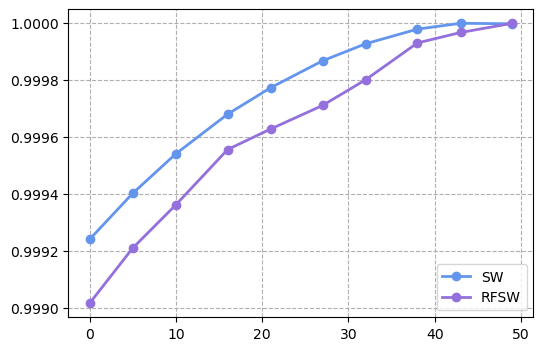

In [20]:
plt.figure(figsize=(6,4))

# plt.plot(vol_idx[:], dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx[:], dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
plt.plot(vol_idx[:], dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

# plt.plot(vol_idx[:], distances_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx[:], distances_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# # plt.plot(vol_idx[:], distances_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
# plt.ylim(-0.05, 1.05)
plt.legend(loc='lower right')
plt.show()

	 0 	 aligned rfsw


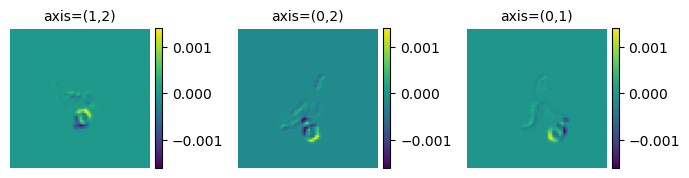

	 5 	 aligned rfsw


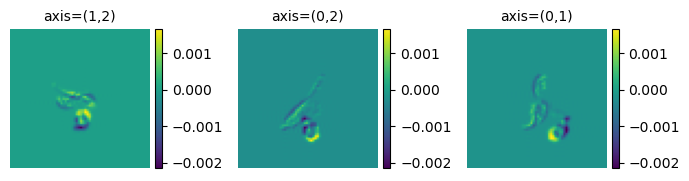

	 10 	 aligned rfsw


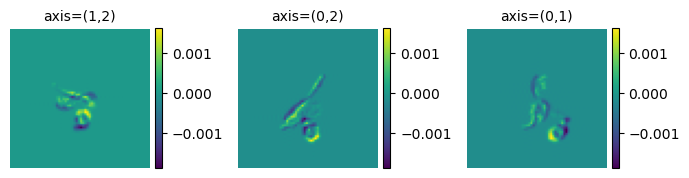

	 16 	 aligned rfsw


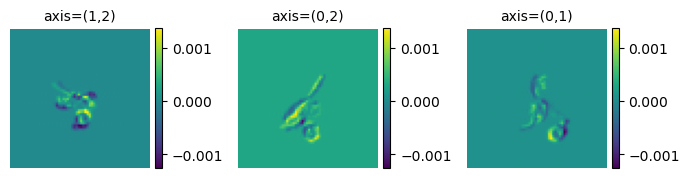

	 21 	 aligned rfsw


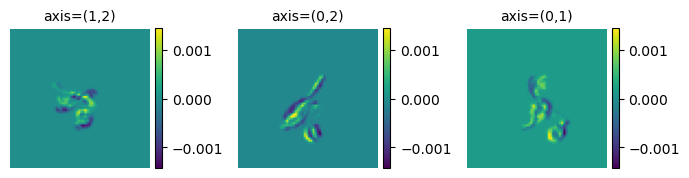

	 27 	 aligned rfsw


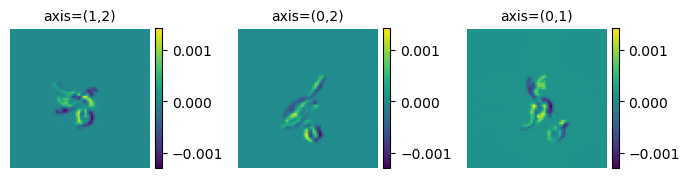

	 32 	 aligned rfsw


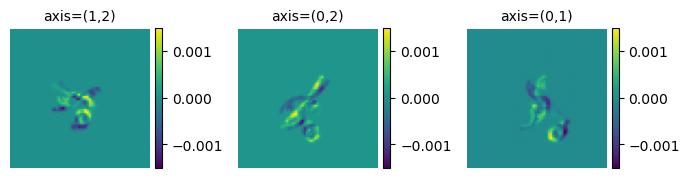

	 38 	 aligned rfsw


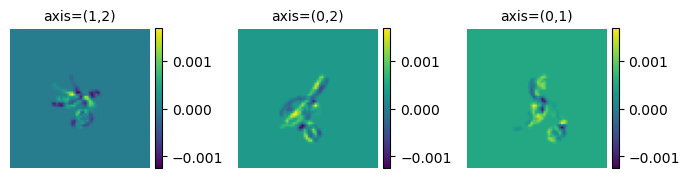

	 43 	 aligned rfsw


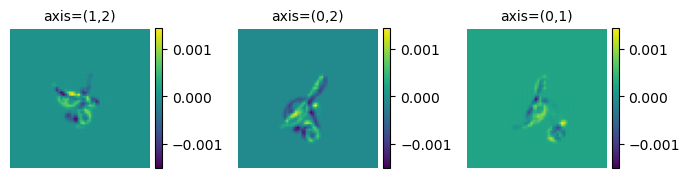

	 49 	 aligned rfsw


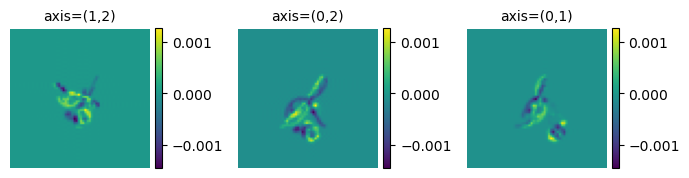

In [17]:
# for k, v in het_vols.items():
#     print('\t', k, '\t', 'unrotated')
#     plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols[k])


# for k, v in het_vols_rotated.items():
#     print('\t', k, '\t', 'rotated')
#     plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols_rotated[k])


# for k, v in het_vols_aligned_l2.items():
#     print('\t', k, '\t', 'aligned l2')
#     plots.orthogonal_2D_projection_plot(F - v)


# for k, v in het_vols_aligned_sw.items():
#     print('\t', k, '\t', 'aligned sw')
#     plots.orthogonal_2D_projection_plot(F - v)


for k, v in het_vols_aligned_rfsw.items():
    print('\t', k, '\t', 'aligned rfsw')
    plots.orthogonal_2D_projection_plot(F - v)

In [18]:
### I think the ordering of the angles from rotmat_to_euler_zyz should be flipped?

for k, idx in enumerate(vol_idx):
    print(idx,':')
    # print('  GT: ', np.rad2deg([omegas[k], betas[k], alphas[k]]))
    print('  L2: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_l2[idx].T)), 1 ))
    print('  SW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_sw[idx].T)), 1 ))
    print('RFSW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_rfsw[idx].T)), 1 ))
    print('\n')

0 :
  L2:  [  0.   0. 180.]
  SW:  [  0.   0. 180.]
RFSW:  [101.2   5.6 -95.6]


5 :
  L2:  [  0.   0. 180.]
  SW:  [  0.   0. 180.]
RFSW:  [ 84.4   5.6 -67.5]


10 :
  L2:  [ 95.6  11.3 -78.8]
  SW:  [ 95.6  11.3 -78.8]
RFSW:  [ 61.9   5.6 -39.4]


16 :
  L2:  [ 95.6  16.9 -73.1]
  SW:  [ 95.6  11.3 -73.1]
RFSW:  [ 84.4  11.3 -56.3]


21 :
  L2:  [ 95.6  22.5 -67.5]
  SW:  [ 95.6  16.9 -67.5]
RFSW:  [ 61.9   5.6 -28.1]


27 :
  L2:  [101.2  28.1 -67.5]
  SW:  [ 95.6  28.1 -56.3]
RFSW:  [45.   5.6 -5.6]


32 :
  L2:  [101.2  39.4 -61.9]
  SW:  [101.3  33.7 -56.3]
RFSW:  [ 67.5  16.9 -16.9]


38 :
  L2:  [33.7 16.9 28.1]
  SW:  [ 95.6  45.  -45. ]
RFSW:  [ 90.   28.1 -39.4]


43 :
  L2:  [61.9 22.5  5.6]
  SW:  [ 95.6  50.6 -39.4]
RFSW:  [ 95.6  61.9 -45. ]


49 :
  L2:  [33.7 16.9 39.4]
  SW:  [ 95.6  61.9 -33.8]
RFSW:  [ 95.6  73.1 -39.4]




In [19]:
# # # The downsampled volume
# with mrcfile.new('Output/ref_vol_65.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols[0].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_rfsw[4].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_sw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_sw[4].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_l2[4].astype('float32'))
 

# with mrcfile.new('Output/vol_49_rot_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_rfsw[9].astype('float32'))

# with mrcfile.new('Output/vol_49_rot_aligned_sw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_sw[9].astype('float32'))

# with mrcfile.new('Output/vol_49_rot_aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_l2[9].astype('float32'))